# 08 - Construire des réseaux : les trois API Keras et la recherche d'architecture

Keras propose trois façons de définir un réseau :

| API | Quand l'utiliser |
|---|---|
| `Sequential` | une pile linéaire de couches (notebooks 02 à 07) |
| **fonctionnelle** | plusieurs entrées / sorties, branches, connexions résiduelles |
| **sous-classement** de `keras.Model` | logique libre dans `call()` (boucles, conditions) |

On termine par une **recherche d'architecture** : quelle profondeur, quelle largeur, quelle activation ?

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from velo_utils import load_splits, plot_history, PALETTE

keras.utils.set_random_seed(42)  # reproductibilité
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [2]:
X_train, X_test, y_train, y_test = load_splits()
Xtr, Xte = X_train.to_numpy(), X_test.to_numpy()
ytr, yte = y_train.to_numpy(), y_test.to_numpy()
n_features = Xtr.shape[1]
print("train :", Xtr.shape, "| test :", Xte.shape)

train : (585, 33) | test : (146, 33)


## 1. API fonctionnelle

On appelle chaque couche sur le tenseur de sortie de la précédente, puis on crée le `Model` avec ses entrées et sorties.
Ce réseau est identique au MLP du notebook 02.

In [3]:
norm = layers.Normalization()
norm.adapt(Xtr)

inputs = keras.Input(shape=(n_features,), name="variables")
x = norm(inputs)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(1, name="locations")(x)

functional = keras.Model(inputs, outputs, name="mlp_fonctionnel")
functional.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mae")
functional.summary()

Model: "mlp_fonctionnel"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ variables (InputLayer)          │ (None, 33)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 33)             │            67 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ locations (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,468 (25.27 KB)

 Trainable params: 6,401 (25.00 KB)

 Non-trainable params: 67 (272.00 B)

In [4]:
h_func = functional.fit(Xtr, ytr, epochs=100, validation_split=0.2, verbose=0)
results = {"MLP fonctionnel": functional.evaluate(Xte, yte, verbose=0)}
results

{'MLP fonctionnel': 0.579211413860321}

## 2. Un réseau à deux branches

L'API fonctionnelle permet des architectures que `Sequential` ne sait pas faire. Ici on sépare les variables
**météo** et **calendrier** : chacune passe dans sa propre branche, puis les deux représentations sont **concaténées**.

In [5]:
meteo_cols = [c for c in X_train.columns
              if c in ("temp", "atemp", "hum", "windspeed") or c.startswith("weathersit")]
cal_cols = [c for c in X_train.columns if c not in meteo_cols]
print("météo      :", meteo_cols)
print("calendrier :", cal_cols)

Xtr_m, Xte_m = X_train[meteo_cols].to_numpy(), X_test[meteo_cols].to_numpy()
Xtr_c, Xte_c = X_train[cal_cols].to_numpy(), X_test[cal_cols].to_numpy()

météo      : ['temp', 'atemp', 'hum', 'windspeed', 'weathersit_1', 'weathersit_2', 'weathersit_3']
calendrier : ['yr', 'holiday', 'workingday', 'season_1', 'season_2', 'season_3', 'season_4', 'mnth_1', 'mnth_2', 'mnth_3', 'mnth_4', 'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11', 'mnth_12', 'weekday_0', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6']


In [6]:
def branch(inp, X, name):
    n = layers.Normalization(name=f"norm_{name}")
    n.adapt(X)
    x = n(inp)
    x = layers.Dense(32, activation="relu", name=f"{name}_1")(x)
    return layers.Dense(16, activation="relu", name=f"{name}_2")(x)

in_meteo = keras.Input(shape=(len(meteo_cols),), name="meteo")
in_cal = keras.Input(shape=(len(cal_cols),), name="calendrier")
merged = layers.Concatenate(name="fusion")([branch(in_meteo, Xtr_m, "meteo"), branch(in_cal, Xtr_c, "cal")])
x = layers.Dense(32, activation="relu")(merged)
out = layers.Dense(1, name="locations")(x)

two_branch = keras.Model(inputs=[in_meteo, in_cal], outputs=out, name="deux_branches")
two_branch.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mae")
two_branch.summary()

Model: "deux_branches"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ meteo (InputLayer)  │ (None, 7)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ calendrier          │ (None, 26)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ norm_meteo          │ (None, 7)         │         15 │ meteo[0][0]       │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ norm_cal            │ (None, 26)        │         53 │ calendrier[0][0]  │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meteo_1 (Dense)     │ (None, 32)        │        256 │ norm_meteo[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cal_1 (Dense)       │ (None, 32)        │        864 │ norm_cal[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meteo_2 (Dense)     │ (None, 16)        │        528 │ meteo_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cal_2 (Dense)       │ (None, 16)        │        528 │ cal_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion              │ (None, 32)        │          0 │ meteo_2[0][0],    │
│ (Concatenate)       │                   │            │ cal_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      1,056 │ fusion[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ locations (Dense)   │ (None, 1)         │         33 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,333 (13.03 KB)

 Trainable params: 3,265 (12.75 KB)

 Non-trainable params: 68 (280.00 B)

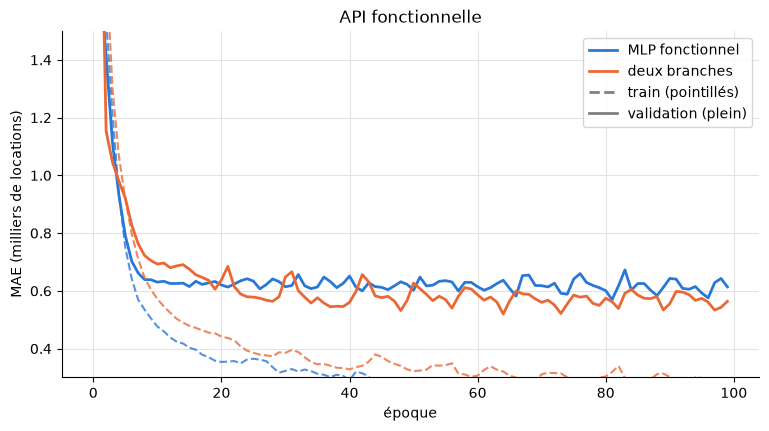

{'MLP fonctionnel': 0.579211413860321, 'deux branches': 0.5456977486610413}

In [7]:
h_two = two_branch.fit([Xtr_m, Xtr_c], ytr, epochs=100, validation_split=0.2, verbose=0)
results["deux branches"] = two_branch.evaluate([Xte_m, Xte_c], yte, verbose=0)

plot_history({"MLP fonctionnel": h_func, "deux branches": h_two}, title="API fonctionnelle", ylim=(0.3, 1.5))
plt.show()
results

Comme chaque branche a sa propre sortie intermédiaire, on peut regarder ce que chacune a appris
en construisant un sous-modèle qui s'arrête à la branche météo :

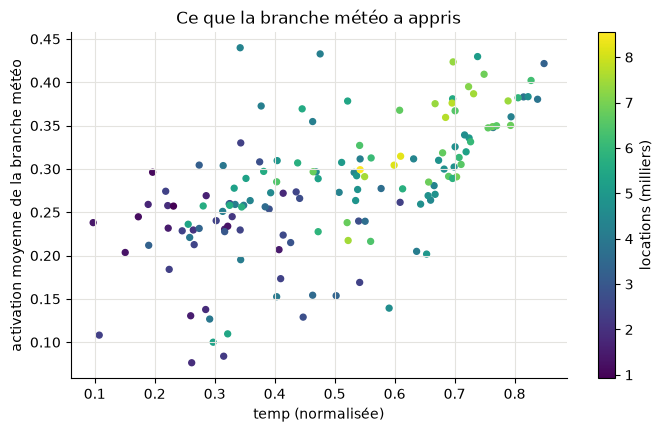

In [8]:
meteo_encoder = keras.Model(in_meteo, two_branch.get_layer("meteo_2").output)
codes = meteo_encoder.predict(Xte_m, verbose=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
sc = ax.scatter(X_test["temp"], codes.mean(axis=1), c=yte, cmap="viridis", s=18)
fig.colorbar(sc, ax=ax, label="locations (milliers)")
ax.set(xlabel="temp (normalisée)", ylabel="activation moyenne de la branche météo",
       title="Ce que la branche météo a appris")
plt.show()

## 3. Sous-classement de `keras.Model`

On écrit les couches dans `__init__` et la propagation avant dans `call`. Le paramètre `training`
permet d'avoir un comportement différent à l'entraînement (ici le Dropout).

In [9]:
class VeloNet(keras.Model):
    def __init__(self, normalizer, units=64, n_hidden=2, dropout=0.1):
        super().__init__()
        self.normalizer = normalizer
        self.hidden = [layers.Dense(units, activation="relu") for _ in range(n_hidden)]
        self.dropout = layers.Dropout(dropout)
        self.head = layers.Dense(1)

    def call(self, x, training=False):
        x = self.normalizer(x)
        for layer in self.hidden:
            x = self.dropout(layer(x), training=training)
        return self.head(x)


keras.utils.set_random_seed(42)
velonet = VeloNet(norm, units=64, n_hidden=3)
velonet.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mae")
h_sub = velonet.fit(Xtr, ytr, epochs=100, validation_split=0.2, verbose=0)
velonet.summary()
results["VeloNet (sous-classe)"] = velonet.evaluate(Xte, yte, verbose=0)
results

Model: "velo_net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 33)             │            67 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,752 (124.04 KB)

 Trainable params: 10,561 (41.25 KB)

 Non-trainable params: 67 (272.00 B)

 Optimizer params: 21,124 (82.52 KB)

{'MLP fonctionnel': 0.579211413860321,
 'deux branches': 0.5456977486610413,
 'VeloNet (sous-classe)': 0.5843539834022522}

## 4. Recherche d'architecture

Combien de couches ? Combien de neurones ? Quelle activation ? On teste toutes les combinaisons
(**grid search**) et on garde la meilleure selon la **validation**. Le test n'est utilisé qu'une seule fois, à la fin.

Chaque modèle s'arrête avec un Early Stopping pour gagner du temps.

In [10]:
def make_mlp(depth, width, activation):
    model = keras.Sequential([keras.Input(shape=(n_features,)), norm])
    for _ in range(depth):
        model.add(layers.Dense(width, activation=activation))
    model.add(layers.Dense(1))
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mae")
    return model

grid, trained = [], {}
start = time.time()
for activation in ["relu", "tanh"]:
    for depth in [1, 2, 3]:
        for width in [16, 64, 256]:
            keras.utils.set_random_seed(42)
            model = make_mlp(depth, width, activation)
            h = model.fit(Xtr, ytr, epochs=300, batch_size=32, validation_split=0.2, verbose=0,
                          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=25,
                                                                   restore_best_weights=True)])
            trained[(activation, depth, width)] = model
            grid.append({"activation": activation, "couches": depth, "neurones": width,
                         "paramètres": model.count_params(),
                         "époques": len(h.history["loss"]),
                         "meilleure MAE val": min(h.history["val_loss"])})
print(f"{len(grid)} modèles entraînés en {time.time() - start:.0f} s")

grid = pd.DataFrame(grid)
grid.sort_values("meilleure MAE val").head(8).round(3)

18 modèles entraînés en 285 s


,activation,couches,neurones,paramètres,époques,meilleure MAE val
17,tanh,3,256,140612,49,0.517
10,tanh,1,64,2308,92,0.518
11,tanh,1,256,9028,82,0.521
13,tanh,2,64,6468,76,0.528
1,relu,1,64,2308,151,0.530
14,tanh,2,256,74820,80,0.531
16,tanh,3,64,10628,52,0.532
2,relu,1,256,9028,94,0.558


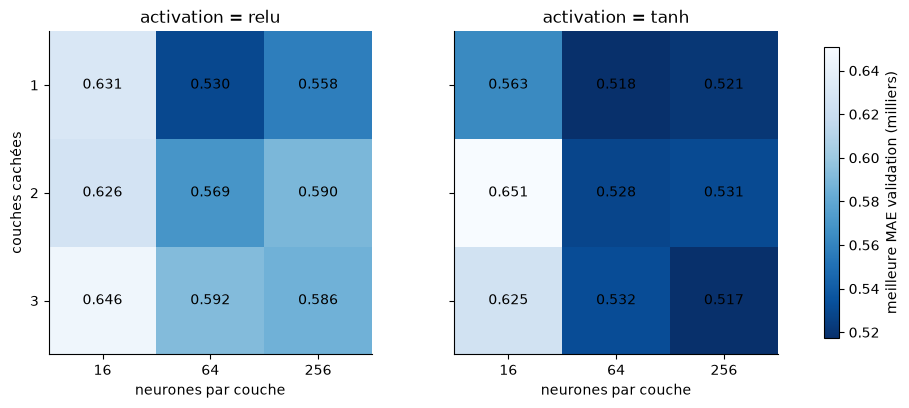

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
vmin, vmax = grid["meilleure MAE val"].min(), grid["meilleure MAE val"].max()
for ax, activation in zip(axes, ["relu", "tanh"]):
    table = grid[grid["activation"] == activation].pivot(index="couches", columns="neurones",
                                                         values="meilleure MAE val")
    im = ax.imshow(table, cmap="Blues_r", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(table.columns)), table.columns)
    ax.set_yticks(range(len(table.index)), table.index)
    ax.grid(False)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f"{table.iloc[i, j]:.3f}", ha="center", va="center")
    ax.set(title=f"activation = {activation}", xlabel="neurones par couche")
axes[0].set_ylabel("couches cachées")
fig.colorbar(im, ax=axes, label="meilleure MAE validation (milliers)", shrink=0.9)
plt.show()

Plus foncé = meilleur. Sur ce petit dataset, les écarts sont faibles : au-delà d'une certaine taille,
ajouter des couches ou des neurones n'apporte plus grand-chose. Le modèle retenu est évalué **une seule fois** sur le test :

In [12]:
best = grid.sort_values("meilleure MAE val").iloc[0]
key = (best["activation"], int(best["couches"]), int(best["neurones"]))
results[f"meilleur de la grille {key}"] = trained[key].evaluate(Xte, yte, verbose=0)

pd.DataFrame(results, index=["MAE test (milliers)"]).T.round(3)

,MAE test (milliers)
MLP fonctionnel,0.579
deux branches,0.546
VeloNet (sous-classe),0.584
"meilleur de la grille ('tanh', 3, 256)",0.550


## À vous de jouer

- Ajoutez une **connexion résiduelle** avec l'API fonctionnelle : `x = layers.Add()([x, layers.Dense(64)(x)])`.
- Dans `VeloNet`, ajoutez un argument `activation` et comparez `relu`, `tanh`, `elu`, `gelu`.
- Élargissez la grille au learning rate (1e-4, 1e-3, 1e-2) et au taux de Dropout.
- Relancez la grille avec une autre graine : le meilleur modèle est-il toujours le même ?